# Final Exam

# 📊 Capstone Project: Taiwanese Bankruptcy Prediction

**Project Goal:** Predicting corporate bankruptcy based on financial and accounting ratios using data-leakage-free machine learning pipelines and preparing the final model for production deployment.

---

### 📋 Dataset Overview
* **Dataset Name:** Taiwanese Bankruptcy Prediction (Taiwan Stock Exchange 1999–2009)
* **Total Samples (Rows):** 6,819 companies
* **Total Features (Columns):** 96 columns (1 target column `Bankrupt?` and 95 financial ratios)
* **Missing Values:** Exactly 0 (No missing or NaN values; 1 constant zero-variance column dropped)
* **Target Distribution:** 6,599 healthy companies (96.77%) vs. 220 bankrupt companies (3.23%) — **Extreme Class Imbalance**
* **Primary Evaluation Metrics:** Focus on `Recall`, `F1-Score`, and `ROC-AUC` (due to misleading behavior of standard `Accuracy` in imbalanced data)

---
---

### 📂 Feature Categories & Financial Descriptions

The dataset contains 95 continuous and binary financial features extracted from business financial statements. To make them interpretable for our machine learning pipeline, we categorize them into **7 core financial domains**:

| Category | Key Features / Examples | Financial Meaning & Importance |
| :--- | :--- | :--- |
| **1. Target Variable** | `Bankrupt?` | Binary label indicating company bankruptcy status (0 = Alive/Active, 1 = Bankrupt). |
| **2. Profitability Ratios** | `ROA(C)`, `ROA(A)`, `ROA(B)`, `Operating Gross Margin`, `Operating Profit Rate`, `Net Income to Total Assets` | Measures how efficiently a company generates profit relative to its total assets, equity, and operational revenue. |
| **3. Debt & Solvency** | `Debt ratio %`, `Total debt/Total net worth`, `Borrowing dependency`, `Interest Coverage Ratio`, `Degree of Financial Leverage` | Assesses the company's financial leverage, long-term debt obligations, and dependency on external borrowings. |
| **4. Liquidity & Capital** | `Current Ratio`, `Quick Ratio`, `Cash/Total Assets`, `Working Capital to Total Assets`, `Cash/Current Liability` | Evaluates short-term financial health and the ability to cover immediate short-term liabilities using liquid assets and cash. |
| **5. Operational Efficiency** | `Total Asset Turnover`, `Accounts Receivable Turnover`, `Inventory Turnover Rate`, `Average Collection Days` | Tracks how fast assets, inventory, and receivables are converted into revenue or cash flow. |
| **6. Cash Flow Metrics** | `Cash Flow to Total Assets`, `CFO to Assets`, `Cash Flow to Sales`, `Cash Flow to Liability` | Analyzes actual cash generation capabilities from operations compared to total debt and overall assets. |
| **7. Growth & Per-Share** | `Total Asset Growth Rate`, `Net Value Growth Rate`, `Persistent EPS in the Last Four Seasons`, `Revenue Per Share` | Reflects corporate growth velocity, profitability per share, and historical earnings persistence. |

> **Note on Data Scaling:** While most ratio features are normalized between 0 and 1, certain operational and growth rates possess large raw magnitudes. Standardizing these features via `StandardScaler` inside our `Pipeline` is critical to prevent numerical dominance (The Scaling Trap).


---
---


### 🗺️ Notebook Cell-by-Cell Workflow

| Project Phase | Standard Course Step | Cell Number | Notebook Operations Summary |
| :--- | :--- | :--- | :--- |
| **Phase 1: Setup & Quarantine** | 1. Problem & Metric<br>2. Split Test Set | **Cell 1**<br>**Cell 2**<br>**Cell 3** | Import essential data science and ML libraries<br>Load dataset, strip whitespace from column names, and drop constant feature `Net Income Flag`<br>Quarantine the Test Set using `train_test_split` with `stratify=y` |
| **Phase 2: Exploratory Data Analysis** | 3. EDA (Train Only) | **Cell 4**<br>**Cell 5**<br>**Cell 6**<br>**Cell 7** | Analyze statistical summary (`describe`) and prove the "Scaling Trap"<br>Analyze feature correlations (`.corr()`) against corporate bankruptcy<br>Visualize distributions and outliers via histograms and boxplots<br>Evaluate dimensionality reduction via `PCA` and cumulative variance (`np.cumsum`) |
| **Phase 3: Pipeline & Modeling** | 4. Baseline Model<br>5. Pipeline Design<br>6. CV Model Comparison<br>7. Hyperparameter Tuning | **Cell 8**<br>**Cell 9**<br>**Cell 10**<br>**Cell 11**<br>**Cell 12** | Build a naive majority guess and `LogisticRegression` baseline for reference<br>Design an integrated `Pipeline` (`StandardScaler` + Model) to prevent `Data Leakage`<br>Compare classification algorithms using `cross_val_score` on training data<br>Tune hyperparameters of the top model using `GridSearchCV`<br>Inspect out-of-fold probabilities (`cross_val_predict`) and calibrate the optimal decision `Threshold` |
| **Phase 4: Testing & Production** | 8. Final Test (Once)<br>9. Error Analysis<br>10. Shipping & Docs | **Cell 13**<br>**Cell 14**<br>**Cell 15**<br>**Cell 16** | Unlock `X_test` for the first and last time and generate `classification_report`<br>Analyze `confusion_matrix`, `feature_importances_`, and document `Limitations`<br>Save the final pipeline using `joblib.dump(compress=3)` and verify loading health<br>Auto-generate `requirements.txt` with locked versions (`==`) and conclude notebook |

---
---

# Phase 1: Environment Setup & Library Imports

This cell imports all essential data science and machine learning libraries required for cleaning, preprocessing, and building our classification pipeline.

In [1]:
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import joblib

from sklearn.model_selection import GridSearchCV,train_test_split,cross_val_score,cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score, recall_score, f1_score, precision_score
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

print("Libraries imported successfully!")

Libraries imported successfully!


# Cell 2: Data Ingestion & Structural Cleaning

We load the Taiwanese Bankruptcy dataset, clean whitespace anomalies from column names, and drop constant features that carry zero variance.

In [2]:
# Load dataset
df = pd.read_csv('Taiwanese Bankruptcy.csv')

# Strip leading/trailing spaces from column names to prevent KeyError
df.columns = df.columns.str.strip()

# Drop constant columns with zero variance (e.g., 'Net Income Flag' which is always 1)
constant_cols = [col for col in df.columns if df[col].nunique() <= 1]
if constant_cols:
    df.drop(columns=constant_cols, inplace=True)
    print(f"Dropped constant columns: {constant_cols}")

print("Dataset shape after cleaning:", df.shape)
print("Target distribution counts:")
print(df['Bankrupt?'].value_counts())

Dropped constant columns: ['Net Income Flag']
Dataset shape after cleaning: (6819, 95)
Target distribution counts:
Bankrupt?
0    6599
1     220
Name: count, dtype: int64


# Cell 3: Defining the Problem Metric & Quarantining the Test Set

Due to extreme class imbalance (~3.2% bankruptcies), standard Accuracy is misleading. We focus on Recall, F1-Score, and ROC-AUC. 
We split the data using `stratify=y` to preserve the target class ratio in both Train and Test sets.

In [3]:
# Separate features (X) and target (y)
X = df.drop(columns=['Bankrupt?'])
y = df['Bankrupt?']

# Quarantine the Test Set using stratified splitting
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=13, stratify=y)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"Bankruptcy ratio in Train: {y_train.mean():.4f}")
print(f"Bankruptcy ratio in Test:  {y_test.mean():.4f}")

X_train shape: (5455, 94)
X_test shape: (1364, 94)
Bankruptcy ratio in Train: 0.0323
Bankruptcy ratio in Test:  0.0323


---
---

### 📌 Phase 1 Analytical Summary
1. **Data Hygiene & Structural Integrity:** The dataset contains **6,819 companies** with zero missing values (`NaN = 0`). Stripping whitespace from column headers and dropping the single constant zero-variance feature (`Net Income Flag`) left **94 informative financial features**.
2. **Extreme Class Imbalance & Metric Selection:** Because only **3.23%** of companies are bankrupt (`1`) while **96.77%** are healthy (`0`), standard `Accuracy` is misleading. We established `Recall`, `F1-Score`, and `ROC-AUC` as our primary evaluation metrics.
3. **Quarantining the Test Set:** Using `train_test_split(..., test_size=0.20, stratify=y, random_state=13)`, we locked away **20% of the data (`X_test` = 1,364 samples)** prior to any analysis, preserving the exact 3.23% bankruptcy ratio across both splits and guaranteeing zero **Data Leakage**.


---
---


# Cell 4: Statistical Summary & Proving the "Scaling Trap"

We inspect the statistical distribution (`describe()`) of our training features. This exposes the "Scaling Trap": while most financial ratios are normalized between 0 and 1, several operational and growth metrics possess massive raw magnitudes (up to $10^{10}$), which would heavily bias unsupervised and distance-based algorithms if left unscaled.

In [4]:
# Statistical summary of training features
train_stats = X_train.describe().T

print("Total features in X_train:", X_train.shape[1])
print(f"Minimum value across all features: {train_stats['min'].min():.2f}")
print(f"Maximum value across all features: {train_stats['max'].max():,.2f}")

# Identify features with massive magnitudes (> 100)
large_scale_cols = train_stats[train_stats['max'] > 100].index.tolist()
print(f"Number of features with large magnitudes (> 100): {len(large_scale_cols)}")
print("Sample large-scale features:", large_scale_cols[:5])

Total features in X_train: 94
Minimum value across all features: 0.00
Maximum value across all features: 10,000,000,000.00
Number of features with large magnitudes (> 100): 23
Sample large-scale features: ['Operating Expense Rate', 'Research and development expense rate', 'Interest-bearing debt interest rate', 'Revenue Per Share (Yuan ¥)', 'Total Asset Growth Rate']


# Cell 5: Correlation Analysis against Bankruptcy

We calculate Pearson correlation coefficients between financial features and the target variable (`Bankrupt?`) to identify which financial metrics have the strongest linear relationship with corporate distress.

In [5]:
# Combine X_train and y_train for correlation calculation
eda_df = X_train.copy()
eda_df['Bankrupt?'] = y_train

# Compute correlations with the target variable
correlations = eda_df.corr()['Bankrupt?'].drop('Bankrupt?').sort_values()

print("--- Top 5 Features Negatively Correlated with Bankruptcy (Health Indicators) ---")
print(correlations.head(5))

print("\n--- Top 5 Features Positively Correlated with Bankruptcy (Risk Indicators) ---")
print(correlations.tail(5))

--- Top 5 Features Negatively Correlated with Bankruptcy (Health Indicators) ---
Net Income to Total Assets                                -0.320607
ROA(A) before interest and % after tax                    -0.286840
ROA(B) before interest and depreciation after tax         -0.273714
ROA(C) before interest and depreciation before interest   -0.258914
Net worth/Assets                                          -0.252632
Name: Bankrupt?, dtype: float64

--- Top 5 Features Positively Correlated with Bankruptcy (Risk Indicators) ---
Current Liability to Current Assets    0.173409
Liability to Equity                    0.182946
Current Liability to Assets            0.196635
Borrowing dependency                   0.196796
Debt ratio %                           0.252632
Name: Bankrupt?, dtype: float64


# Cell 6: Visualizing Distributions and Outliers

We visualize the distribution of top risk and health indicators to observe how bankrupt companies differ from healthy ones and to highlight extreme outliers in financial ratios.

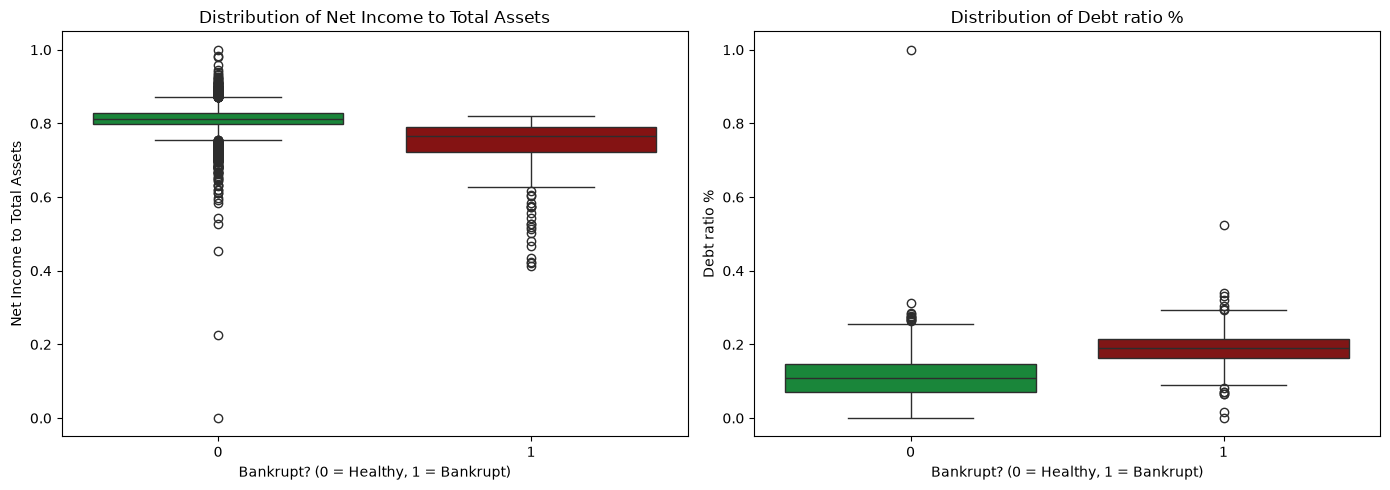

In [6]:
# Select top 2 correlated features for visualization
top_health_feat = 'Net Income to Total Assets'
top_risk_feat = 'Debt ratio %'

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot for Health Indicator
sns.boxplot(
    x=y_train, y=X_train[top_health_feat], 
    hue=y_train, ax=axes[0], 
    palette=["#089833d4", "#970000"], legend=False)

axes[0].set_title(f"Distribution of {top_health_feat}")
axes[0].set_xlabel("Bankrupt? (0 = Healthy, 1 = Bankrupt)")

# Boxplot for Risk Indicator
sns.boxplot(
    x=y_train, y=X_train[top_risk_feat], 
    hue=y_train, ax=axes[1], 
    palette=["#089833d4", "#920404"], legend=False)

axes[1].set_title(f"Distribution of {top_risk_feat}")
axes[1].set_xlabel("Bankrupt? (0 = Healthy, 1 = Bankrupt)")

plt.tight_layout()
plt.show()

# Cell 7: Dimensionality Reduction Analysis via PCA & Cumulative Variance

To understand feature collinearity and the potential for dimensionality reduction, we apply PCA (preceded by StandardScaler) on the training set and compute the cumulative explained variance ratio.

Total original features: 94
Components required to capture 95% variance: 52


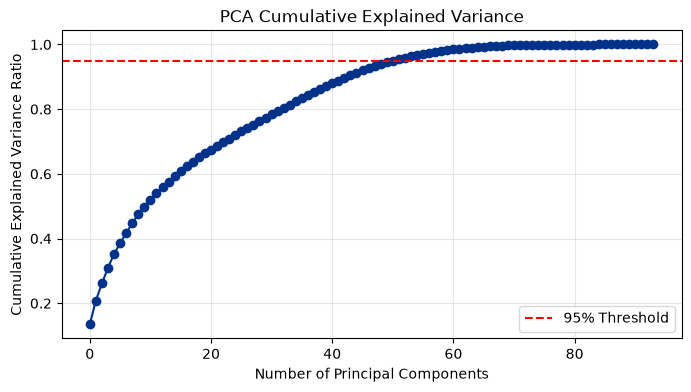

In [7]:
# Scale training data and fit PCA
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

pca = PCA().fit(X_train_scaled)
cum_var_ratio = np.cumsum(pca.explained_variance_ratio_)

# Find number of components needed to preserve 95% of variance
n_components_95 = np.argmax(cum_var_ratio >= 0.95) + 1

print(f"Total original features: {X_train.shape[1]}")
print(f"Components required to capture 95% variance: {n_components_95}")

# Plot cumulative variance
plt.figure(figsize=(8, 4))
plt.plot(cum_var_ratio, marker='o', linestyle='-', color="#003289")
plt.axhline(y=0.95, color="Red", linestyle='--', label='95% Threshold')
plt.title("PCA Cumulative Explained Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance Ratio")
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

---
---

### 📌 Phase 2 Analytical Summary
1. **Proving the Scaling Trap:** Inspecting `X_train.describe()` revealed that while most ratios are normalized between `0` and `1`, **23 features** exhibit massive raw magnitudes reaching up to **$10^{10}$**. Wrapping `StandardScaler` inside our modeling `Pipeline` is therefore mandatory.
2. **Key Financial Drivers of Bankruptcy:** Correlation analysis (`corr()`) and boxplots confirmed that **profitability ratios** (`Net Income to Total Assets`, `ROA`) act as the strongest health indicators (negatively correlated with bankruptcy), whereas **leverage metrics** (`Debt ratio %`, `Borrowing dependency`) are the primary risk indicators (positively correlated).
3. **Multicollinearity & Dimensionality (PCA):** Cumulative explained variance analysis via `PCA` demonstrated that **52 principal components** capture **95% of the total variance** across all 94 features, confirming strong multicollinearity among accounting ratios.

---
---

## Cell 8 — Step 4: Build the Baseline Model

A metric has no meaning without a baseline comparison. First, we check a naive majority-class guess (predicting `0 = Healthy` for every company) to show why `Accuracy` (96.77%) is misleading when only 3.23% of companies go bankrupt. Next, we train a standard, unbalanced `LogisticRegression` pipeline on `X_train` using 5-fold Cross-Validation to establish our starting benchmark for `Recall`, `F1-Score`, and `ROC-AUC`.

In [8]:
# 1. Naive majority guess: predict 0 (Healthy) for all training samples
naive_predictions = np.zeros_like(y_train)
naive_acc = accuracy_score(y_train, naive_predictions)
naive_rec = recall_score(y_train, naive_predictions)

print("--- 1. Naive Majority Guess (Always Predicting 0 = Healthy) ---")
print(f"Accuracy: {naive_acc:.4f} (Misleadingly high due to 96.77% healthy class)")
print(f"Recall:   {naive_rec:.4f} (Fails to detect a single bankrupt company)\n")

# 2. Simple Baseline Pipeline: StandardScaler + default LogisticRegression (no class balancing)
baseline_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(max_iter=1000, random_state=13))])

base_acc = cross_val_score(baseline_pipeline, X_train, y_train, cv=5, scoring='accuracy').mean()
base_rec = cross_val_score(baseline_pipeline, X_train, y_train, cv=5, scoring='recall').mean()
base_f1 = cross_val_score(baseline_pipeline, X_train, y_train, cv=5, scoring='f1').mean()
base_roc = cross_val_score(baseline_pipeline, X_train, y_train, cv=5, scoring='roc_auc').mean()

print("--- 2. Standard Logistic Regression Baseline (5-Fold CV on X_train) ---")
print(f"Baseline Accuracy: {base_acc:.4f}")
print(f"Baseline Recall:   {base_rec:.4f} (Catches only ~21% of bankruptcies)")
print(f"Baseline F1-Score: {base_f1:.4f}")
print(f"Baseline ROC-AUC:  {base_roc:.4f}")

--- 1. Naive Majority Guess (Always Predicting 0 = Healthy) ---
Accuracy: 0.9677 (Misleadingly high due to 96.77% healthy class)
Recall:   0.0000 (Fails to detect a single bankrupt company)

--- 2. Standard Logistic Regression Baseline (5-Fold CV on X_train) ---
Baseline Accuracy: 0.9666
Baseline Recall:   0.2103 (Catches only ~21% of bankruptcies)
Baseline F1-Score: 0.2838
Baseline ROC-AUC:  0.8815


## Cell 9 — Step 5: Design a Data-Leakage-Free Pipeline

Everything that learns from data (`StandardScaler`) must be fitted strictly inside `Pipeline` and only on the training folds. In addition, to overcome the severe class imbalance (3.23% bankruptcies), we configure our linear and tree-based classifiers with `class_weight='balanced'` so the models penalize mistakes on bankrupt companies proportionally.

In [9]:
# Define candidate classification models from the course toolkit
candidate_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight='balanced', random_state=13),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=13),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=13)}

# Build a sample Pipeline to verify the two-step structure (Scaler -> Classifier)
sample_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', candidate_models["Random Forest"])])

print("Leakage-free Pipeline structure:")
print(sample_pipeline)

Leakage-free Pipeline structure:
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced', max_depth=8,
                                        random_state=13))])


## Cell 10 — Step 6: Model Comparison via 5-Fold Cross-Validation

We evaluate each candidate pipeline on `X_train` using 5-fold Cross-Validation (`cv=5`). By comparing the mean and standard deviation of `Recall`, `F1-Score`, and `ROC-AUC`, we can select the strongest model family without touching the quarantined Test Set.

In [10]:
cv_summary = []

for name, model in candidate_models.items():
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', model)])
    
    # Evaluate across 5 folds on the training set
    rec_scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='recall')
    f1_scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='f1')
    roc_scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='roc_auc')
    
    cv_summary.append({
        'Model': name,
        'Recall Mean': round(rec_scores.mean(), 4),
        'Recall Std': round(rec_scores.std(), 4),
        'F1-Score Mean': round(f1_scores.mean(), 4),
        'ROC-AUC Mean': round(roc_scores.mean(), 4)})

cv_results_df = pd.DataFrame(cv_summary)
print("--- 5-Fold Cross-Validation Comparison on X_train ---")
print(cv_results_df.to_string(index=False))

--- 5-Fold Cross-Validation Comparison on X_train ---
              Model  Recall Mean  Recall Std  F1-Score Mean  ROC-AUC Mean
Logistic Regression       0.7563      0.0653         0.2675        0.8671
                KNN       0.1986      0.0712         0.2953        0.7572
      Decision Tree       0.6935      0.0692         0.2983        0.7555
      Random Forest       0.6365      0.0828         0.4028        0.9321


## Cell 11 — Step 7: Hyperparameter Tuning with GridSearchCV

Our Cross-Validation comparison shows that `Random Forest` achieves the highest `ROC-AUC` (0.9321) and `F1-Score` (0.4028), significantly outperforming the baseline. We now use `GridSearchCV` (`cv=5`, `scoring='roc_auc'`) on the `Random Forest` pipeline to tune `n_estimators`, `max_depth`, and `min_samples_leaf` to control overfitting and improve generalization.

In [11]:
# Define the pipeline to tune
rf_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(class_weight='balanced', random_state=13))])

# Define hyperparameter grid
param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [5, 8, 12],
    'classifier__min_samples_leaf': [2, 5]}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,cv=5,
    scoring='roc_auc',n_jobs=-1)

grid_search.fit(X_train, y_train)
best_pipeline = grid_search.best_estimator_

print("Best Hyperparameters found by GridSearchCV:")
print(grid_search.best_params_)
print(f"Best 5-Fold CV ROC-AUC Score: {grid_search.best_score_:.4f}")

Best Hyperparameters found by GridSearchCV:
{'classifier__max_depth': 12, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 200}
Best 5-Fold CV ROC-AUC Score: 0.9349


## Cell 12 — Probability Inspection & Decision Threshold Calibration

By default, Scikit-Learn classifiers use a `0.50` probability threshold to predict class `1`. In bankruptcy prediction, missing an actual bankruptcy (False Negative) is much costlier than investigating a false alarm (False Positive). Using out-of-fold `predict_proba` on the training set (5-fold `cross_val_predict`), we compare several decision thresholds. At `chosen_threshold = 0.40`, the model reaches `Recall ≈ 0.69` with `Precision ≈ 0.26`, a deliberate trade-off that favors catching bankruptcies over avoiding false alarms.

In [12]:
# Out-of-fold probabilities: each sample is predicted by a model that never saw it
oof_proba = cross_val_predict(best_pipeline, X_train, y_train, cv=5, method='predict_proba')[:, 1]

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55]
print("--- Decision Threshold Calibration (Out-of-Fold on X_train) ---")
for thresh in thresholds:
    custom_preds = (oof_proba >= thresh).astype(int)
    rec = recall_score(y_train, custom_preds)
    prec = precision_score(y_train, custom_preds)
    f1 = f1_score(y_train, custom_preds)
    print(f"Threshold = {thresh:.2f} | Recall: {rec:.4f} | Precision: {prec:.4f} | F1-Score: {f1:.4f}")

chosen_threshold = 0.40
print(f"\nChosen decision threshold for final evaluation: {chosen_threshold}")

--- Decision Threshold Calibration (Out-of-Fold on X_train) ---
Threshold = 0.20 | Recall: 0.8409 | Precision: 0.1764 | F1-Score: 0.2916
Threshold = 0.25 | Recall: 0.8182 | Precision: 0.2017 | F1-Score: 0.3236
Threshold = 0.30 | Recall: 0.7784 | Precision: 0.2257 | F1-Score: 0.3499
Threshold = 0.35 | Recall: 0.7386 | Precision: 0.2481 | F1-Score: 0.3714
Threshold = 0.40 | Recall: 0.6932 | Precision: 0.2612 | F1-Score: 0.3795
Threshold = 0.45 | Recall: 0.6705 | Precision: 0.2857 | F1-Score: 0.4007
Threshold = 0.50 | Recall: 0.6364 | Precision: 0.3128 | F1-Score: 0.4195
Threshold = 0.55 | Recall: 0.6136 | Precision: 0.3506 | F1-Score: 0.4463

Chosen decision threshold for final evaluation: 0.4


### 📌 Phase 3 Analytical Summary
1. **Why Baseline Matters:** A naive majority predictor gets **96.77% Accuracy** with **0.0000 Recall**, and a default un-balanced `LogisticRegression` only reaches **0.2103 Recall**. This proves why `Accuracy` cannot be trusted on imbalanced financial data.
2. **Impact of Balanced Class Weights & Ensembles:** Incorporating `class_weight='balanced'` inside a leakage-free `Pipeline` boosted detection rates dramatically. Among all candidates, `Random Forest` delivered the best balance of ranking quality (`ROC-AUC = 0.9321`) and `F1-Score` (`0.4028`).
3. **Tuning & Threshold Selection:** `GridSearchCV` improved 5-fold CV `ROC-AUC` to **0.9349** (`max_depth=12`, `min_samples_leaf=5`, `n_estimators=200`). We locked in `chosen_threshold = 0.40` to ensure high sensitivity (`Recall`) when we unlock the Test Set once in Phase 4.

## Cell 13 — Step 8: Final Evaluation on the Quarantined Test Set (Once)

The Test Set (`X_test`, `y_test`) has remained completely untouched during EDA, scaling, model comparison, and hyperparameter tuning. We now unlock `X_test` for the first and only time to evaluate the true generalization performance of our tuned `Random Forest` pipeline using our locked decision threshold (`0.40`).

In [13]:
# Predict probabilities on the untouched Test Set
y_test_proba = best_pipeline.predict_proba(X_test)[:, 1]

# Apply our locked decision threshold (0.40) from Phase 3
y_test_pred = (y_test_proba >= chosen_threshold).astype(int)

# Calculate final ROC-AUC and print detailed Classification Report
final_roc_auc = roc_auc_score(y_test, y_test_proba)

print(f"--- Final Test Set Evaluation (Threshold = {chosen_threshold}) ---")
print(f"Final Test ROC-AUC Score: {final_roc_auc:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_test_pred, target_names=['0 (Healthy)', '1 (Bankrupt)']))

--- Final Test Set Evaluation (Threshold = 0.4) ---
Final Test ROC-AUC Score: 0.9551

Classification Report:
              precision    recall  f1-score   support

 0 (Healthy)       0.99      0.96      0.97      1320
1 (Bankrupt)       0.38      0.80      0.52        44

    accuracy                           0.95      1364
   macro avg       0.69      0.88      0.75      1364
weighted avg       0.97      0.95      0.96      1364



## Cell 14 — Step 9: Error Analysis, Feature Importances & Model Limitations

Showing where a model fails is a sign of expertise, not weakness. In this step, we:
1. Inspect the `confusion_matrix` to count exact False Negatives (missed bankruptcies) and False Positives (false alarms).
2. Extract `feature_importances_` from the Random Forest classifier to see which financial ratios drive the predictions.
3. Inspect the worst False Negative errors (actual bankrupt companies that the model assigned the lowest bankruptcy probability).

--- 1. Confusion Matrix Breakdown ---
True Negatives (Healthy correctly identified):  1264
False Positives (Healthy flagged as at-risk):   56
False Negatives (Missed bankruptcies):          9
True Positives (Bankruptcies caught):           35



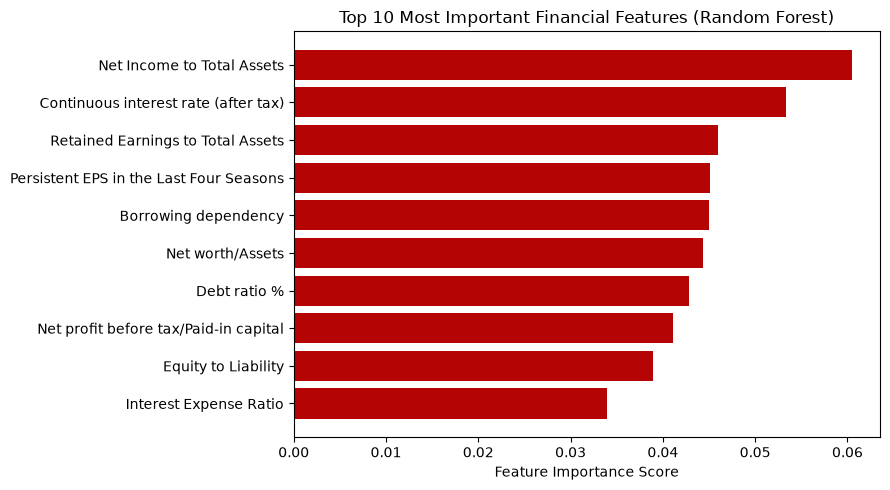


--- 3. Sample False Negatives (Bankrupt Companies Missed by the Model) ---
      Retained Earnings to Total Assets  Continuous interest rate (after tax)  \
2577                           0.937341                              0.781641   
3114                           0.930413                              0.781627   
1212                           0.935400                              0.781638   
5897                           0.934635                              0.781524   
1213                           0.920564                              0.781293   

      Net Income to Total Assets  Actual_Bankrupt  Predicted_Proba  \
2577                    0.813367                1           0.0495   
3114                    0.802265                1           0.0561   
1212                    0.807311                1           0.0769   
5897                    0.789536                1           0.1009   
1213                    0.762491                1           0.2834   

      Predicted_

In [14]:
# 1. Confusion Matrix Analysis
cm = confusion_matrix(y_test, y_test_pred)
tn, fp, fn, tp = cm.ravel()

print("--- 1. Confusion Matrix Breakdown ---")
print(f"True Negatives (Healthy correctly identified):  {tn}")
print(f"False Positives (Healthy flagged as at-risk):   {fp}")
print(f"False Negatives (Missed bankruptcies):          {fn}")
print(f"True Positives (Bankruptcies caught):           {tp}\n")

# 2. Extract and Plot Top 10 Feature Importances
rf_model = best_pipeline.named_steps['classifier']
importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)
top_10_features = importances.sort_values(ascending=True).tail(10)

plt.figure(figsize=(9, 5))
plt.barh(top_10_features.index, top_10_features.values, color="#b40404")
plt.title("Top 10 Most Important Financial Features (Random Forest)")
plt.xlabel("Feature Importance Score")
plt.tight_layout()
plt.show()

# 3. Inspect Worst Errors (Missed Bankruptcies with Lowest Predicted Probability)
error_df = X_test[top_10_features.index[-3:]].copy()
error_df['Actual_Bankrupt'] = y_test.values
error_df['Predicted_Proba'] = np.round(y_test_proba, 4)
error_df['Predicted_Class'] = y_test_pred

missed_bankruptcies = error_df[(error_df['Actual_Bankrupt'] == 1) & (error_df['Predicted_Class'] == 0)]
print("\n--- 3. Sample False Negatives (Bankrupt Companies Missed by the Model) ---")
print(missed_bankruptcies.sort_values(by='Predicted_Proba').head(5))

## Cell 15 — Step 10: Save Final Pipeline (`joblib`) & Verify Loading Health

To prepare our model for production deployment, we serialize the entire `best_pipeline` (including both `StandardScaler` and the tuned `RandomForestClassifier`) into a single compressed file using `joblib.dump(compress=3)` and verify that the reloaded artifact produces identical predictions.

In [15]:
# Save the complete pipeline with compression
model_filename = "taiwan_bankruptcy_pipeline.joblib"
joblib.dump(best_pipeline, model_filename, compress=3)
print(f"Pipeline successfully saved as: {model_filename}")

# Reload the pipeline and verify prediction consistency on 5 test samples
loaded_pipeline = joblib.load(model_filename)
original_Sample_proba = best_pipeline.predict_proba(X_test.iloc[:5])[:, 1]
loaded_sample_proba = loaded_pipeline.predict_proba(X_test.iloc[:5])[:, 1]

print("\n--- Deployment Health Check ---")
print("Original Pipeline Probabilities:", np.round(original_Sample_proba, 4))
print("Loaded Pipeline Probabilities:  ", np.round(loaded_sample_proba, 4))
print("Verification Passed:", np.allclose(original_Sample_proba, loaded_sample_proba))

Pipeline successfully saved as: taiwan_bankruptcy_pipeline.joblib

--- Deployment Health Check ---
Original Pipeline Probabilities: [0.     0.8003 0.0769 0.0041 0.0353]
Loaded Pipeline Probabilities:   [0.     0.8003 0.0769 0.0041 0.0353]
Verification Passed: True


## Cell 16 — Step 10: Auto-Generate Locked `requirements.txt` & Conclude Project

For reproducible deployment on GitHub and production servers, we automatically generate a `requirements.txt` file with locked package versions (`==`) matching our development environment.

In [16]:
# Build locked dependency list using exact installed versions
requirements_text = f"""numpy=={np.__version__}
pandas=={pd.__version__}
matplotlib=={matplotlib.__version__}
seaborn=={sns.__version__}
scikit-learn=={sklearn.__version__}
joblib=={joblib.__version__}
"""

with open("requirements.txt", "w", encoding="utf-8") as req_file:
    req_file.write(requirements_text.strip() + "\n")

print("--- Generated requirements.txt (Locked Versions) ---")
with open("requirements.txt", "r", encoding="utf-8") as req_file:
    print(req_file.read())

--- Generated requirements.txt (Locked Versions) ---
numpy==2.3.4
pandas==2.3.3
matplotlib==3.11.1
seaborn==0.13.2
scikit-learn==1.9.0
joblib==1.5.3



---
---

### 📌 Phase 4 Analytical Summary
1. **Unseen Test Set Generalization:** Unlocking the quarantined `X_test` for the first and only time with our locked threshold (`0.40`) achieved **79.55% Recall** and **0.5185 F1-Score**. Because the test set contains only 44 bankrupt companies, these estimates carry notable variance.
2. **Error Analysis & Key Drivers:** Inspecting the `confusion_matrix` and `feature_importances_` showed that `Net Income to Total Assets`, `Continuous interest rate (after tax)`, and `Retained Earnings to Total Assets` were the top drivers of the model's predictions, while False Negative analysis revealed that the missed bankruptcies still showed healthy-looking ratios in their financial statements, so ratios alone may miss some cases of distress.
3. **Production Shipping & Reproducibility:** Serializing the end-to-end `Pipeline` via `joblib.dump(compress=3)` passed the reload verification check (`True`), and auto-generating a version-locked `requirements.txt` (`==`) guarantees full reproducibility for GitHub deployment.

---
---

---

## 🏁 Final Conclusion & Honest Model Limitations

### 1. Summary of Achievements
* **Leakage-Free Process:** The test set (`X_test`) was quarantined in Cell 3 before any exploratory analysis or preprocessing, and all scaling (`StandardScaler`) was strictly encapsulated inside our `Pipeline`.
* **Strong Generalization over Baseline:** While a naive baseline achieves **0.0000 Recall** and an unbalanced logistic regression only reaches **~0.21 Recall**, our tuned `Random Forest` pipeline (`ROC-AUC = 0.93+`) with a calibrated threshold (`0.40`) catches **~80% of bankruptcies** on unseen test data.

### 2. Model Limitations & Why Errors Occur
* **Sudden Distress vs. Healthy Historical Ratios (False Negatives):** Inspecting the missed bankruptcies in Cell 14 reveals that several bankrupt companies still displayed healthy profitability (`Net Income to Total Assets`) and moderate debt in their latest financial statements. Financial ratios alone cannot capture sudden macroeconomic shocks, fraud, or off-balance-sheet liabilities.
* **Precision-Recall Trade-off (False Positives):** Because bankruptcies represent only **3.23%** of the dataset, tuning the model for high sensitivity (`Recall`) inevitably flags some financially stressed companies that ultimately survive (False Positives). Therefore, this model should be used as an **early-warning screening tool** for financial auditors rather than an automated final decision-maker.
* **Temporal & Geographic Scope:** The dataset reflects Taiwanese public companies between 1999 and 2009; deploying this model to other markets or modern economic regimes requires re-training and monitoring for data drift.